# Projet : Modèle de scoring de fidélité client

**Auteurs :** Bakou, Antoine, Jonathan

## Contexte

Dans un contexte e-commerce très concurrentiel, fidéliser un client coûte en moyenne 5 fois moins cher que d'en acquérir un nouveau. Ce projet vise à construire un modèle de classification supervisée permettant de prédire si un client est susceptible de churner (se désabonner), et d'en dériver un score de fidélité exploitable par les équipes CRM et marketing.

**Dataset :** [E-Commerce Customer Churn Dataset (Kaggle)](https://www.kaggle.com/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction)

## 0. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_val_predict)
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

## 1. Chargement et exploration initiale

In [2]:
# La 1re feuille du fichier est le dictionnaire des données ('Data Dict') : on lit 'E Comm'
df = pd.read_excel('E Commerce Dataset.xlsx', sheet_name='E Comm')

print("=== Dimensions du dataset ===")
print(df.shape)

print("\n=== Aperçu des premières lignes ===")
print(df.head())

print("\n=== Types de variables ===")
print(df.dtypes)

print("\n=== Statistiques descriptives ===")
print(df.describe())

print("\n=== Valeurs manquantes ===")
missing = df.isnull().sum()
print(missing[missing > 0])

=== Dimensions du dataset ===
(5630, 20)

=== Aperçu des premières lignes ===
   CustomerID  Churn  Tenure PreferredLoginDevice  CityTier  WarehouseToHome  \
0       50001      1     4.0         Mobile Phone         3              6.0   
1       50002      1     NaN                Phone         1              8.0   
2       50003      1     NaN                Phone         1             30.0   
3       50004      1     0.0                Phone         3             15.0   
4       50005      1     0.0                Phone         1             12.0   

  PreferredPaymentMode  Gender  HourSpendOnApp  NumberOfDeviceRegistered  \
0           Debit Card  Female             3.0                         3   
1                  UPI    Male             3.0                         4   
2           Debit Card    Male             2.0                         4   
3           Debit Card    Male             2.0                         4   
4                   CC    Male             NaN               

## 2. Nettoyage et préparation des données

In [3]:
# 2.1 Mise de côté de l'identifiant client (non prédictif, mais nécessaire pour l'export CRM)
customer_ids = df.pop('CustomerID')

# 2.2 Harmonisation des modalités redondantes (même réalité, libellés différents)
df['PreferredLoginDevice'] = df['PreferredLoginDevice'].replace({'Phone': 'Mobile Phone'})
df['PreferredPaymentMode'] = df['PreferredPaymentMode'].replace({'CC': 'Credit Card',
                                                                 'COD': 'Cash on Delivery'})
df['PreferedOrderCat'] = df['PreferedOrderCat'].replace({'Mobile': 'Mobile Phone'})

# 2.3 Valeurs manquantes
# Elles ne concernent que des variables numériques. Elles ne sont PAS imputées ici : calculer
# les médianes sur tout le dataset ferait fuiter de l'information du jeu de test vers
# l'entraînement. L'imputation par la médiane est intégrée au pipeline de modélisation
# (section 5), où les médianes sont apprises sur les seules données d'entraînement.

# 2.4 Encodage des variables catégorielles
cat_cols = df.select_dtypes(exclude='number').columns
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

## 3. Analyse exploratoire (EDA)

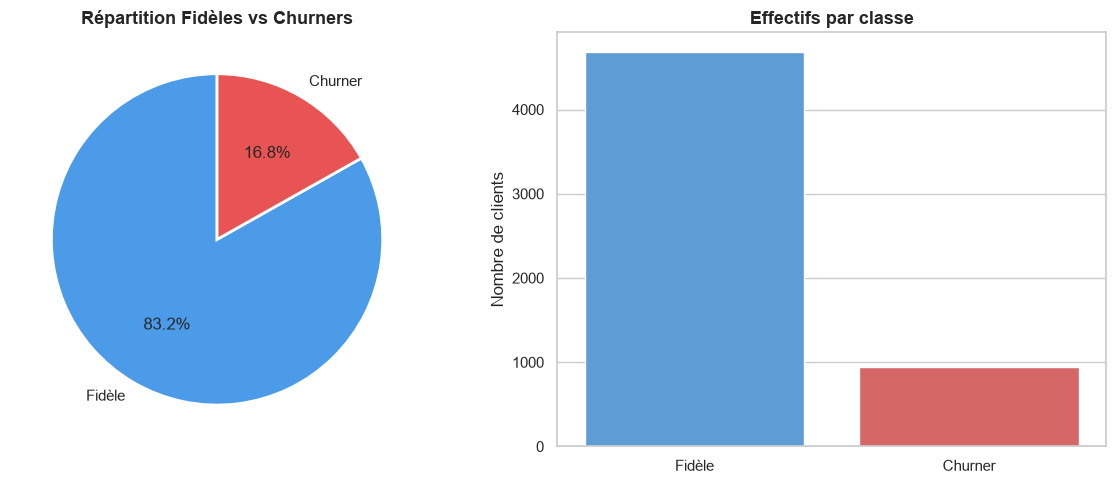

In [4]:
# 3.1 Distribution de la variable cible (Churn)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

churn_counts = df['Churn'].value_counts().sort_index()
axes[0].pie(churn_counts, labels=['Fidèle', 'Churner'],
            autopct='%1.1f%%', colors=['#4C9BE8', '#E85454'],
            startangle=90, wedgeprops=dict(edgecolor='white', linewidth=2))
axes[0].set_title("Répartition Fidèles vs Churners", fontsize=13, fontweight='bold')

sns.countplot(x='Churn', data=df, hue='Churn', palette=['#4C9BE8', '#E85454'],
              legend=False, ax=axes[1])
axes[1].set_xticklabels(['Fidèle', 'Churner'])
axes[1].set_title("Effectifs par classe", fontsize=13, fontweight='bold')
axes[1].set_xlabel("")
axes[1].set_ylabel("Nombre de clients")

plt.tight_layout()
plt.savefig('1_distribution_churn.png', dpi=150, bbox_inches='tight')
plt.show()

**Analyse – Distribution de la variable cible**
- Le dataset est déséquilibré : 83,2 % de clients fidèles contre 16,8 % de churners.
- Ce déséquilibre justifie l'utilisation de SMOTE lors de la phase de modélisation pour
  éviter que le modèle ne soit biaisé vers la classe majoritaire.

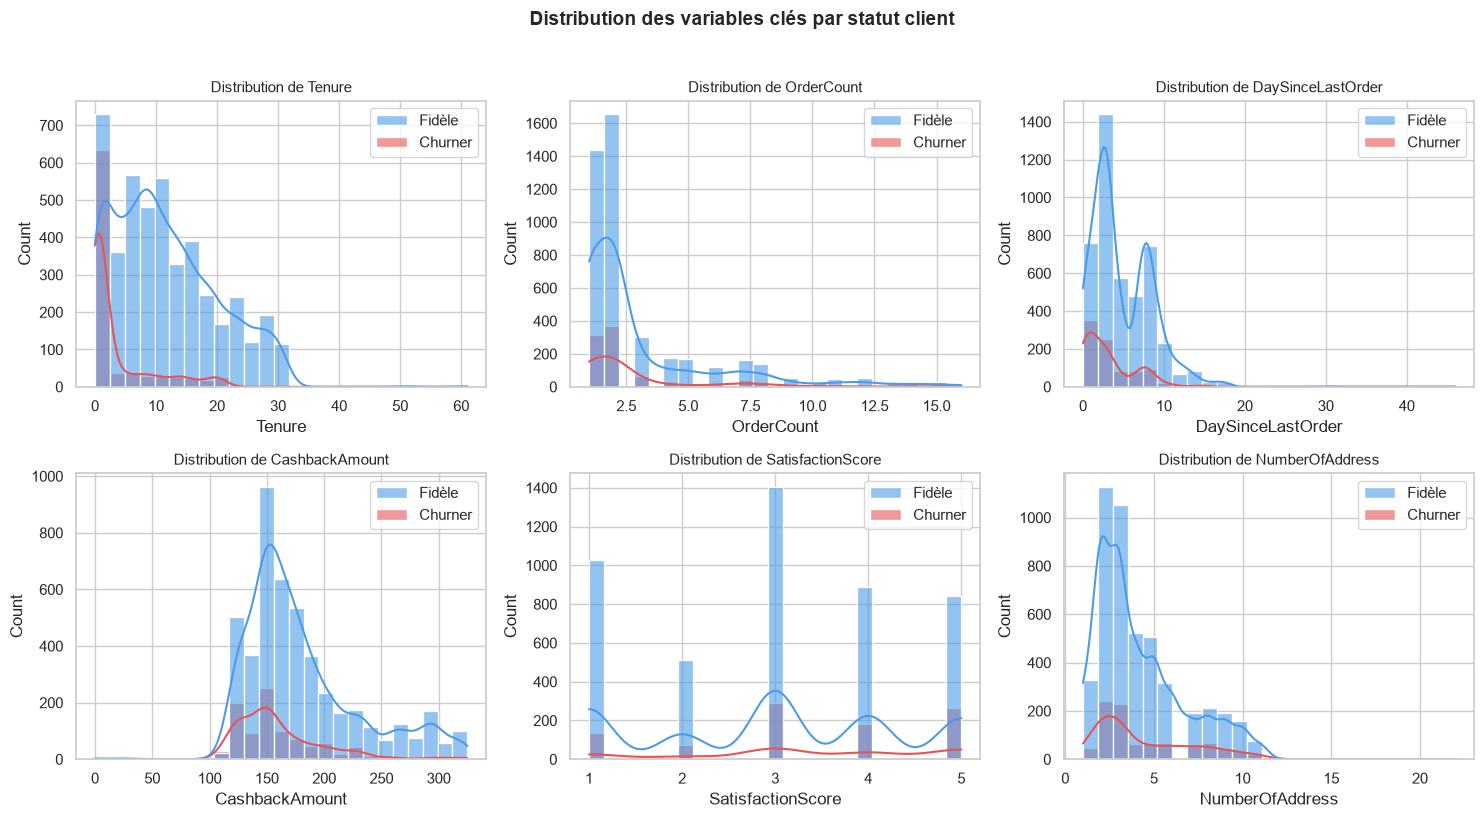

In [5]:
# 3.2 Analyse des variables numériques clés
num_features = ['Tenure', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount',
                'SatisfactionScore', 'NumberOfAddress']
# Garder seulement celles qui existent dans le dataset
num_features = [c for c in num_features if c in df.columns][:6]

if num_features:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()
    for i, col in enumerate(num_features):
        sns.histplot(data=df, x=col, hue='Churn', bins=25,
                     palette=['#4C9BE8', '#E85454'], kde=True, ax=axes[i], alpha=0.6)
        axes[i].set_title(f"Distribution de {col}", fontsize=11)
        # Renommer les entrées de la légende seaborn (ax.legend([...]) inverserait les libellés)
        leg = axes[i].get_legend()
        leg.set_title("")
        for txt, label in zip(leg.get_texts(), ['Fidèle', 'Churner']):
            txt.set_text(label)
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle("Distribution des variables clés par statut client", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('2_distributions_variables.png', dpi=150, bbox_inches='tight')
    plt.show()

**Analyse – Distributions par statut client**
- Les churners sont très majoritairement des clients récents : ancienneté (Tenure) médiane
  de 1 mois contre 10 mois chez les fidèles.
- Le nombre de commandes (OrderCount) seul discrimine peu (médiane de 2 dans les deux groupes).
- Les churners ont commandé plus récemment (DaySinceLastOrder médian de 2 jours contre 4) :
  le churn intervient tôt, juste après les premiers achats.
- Contre-intuitif : le score de satisfaction moyen est légèrement plus élevé chez les churners
  (3,39 contre 3,00). Cette variable déclarative est donc un mauvais signal d'alerte.

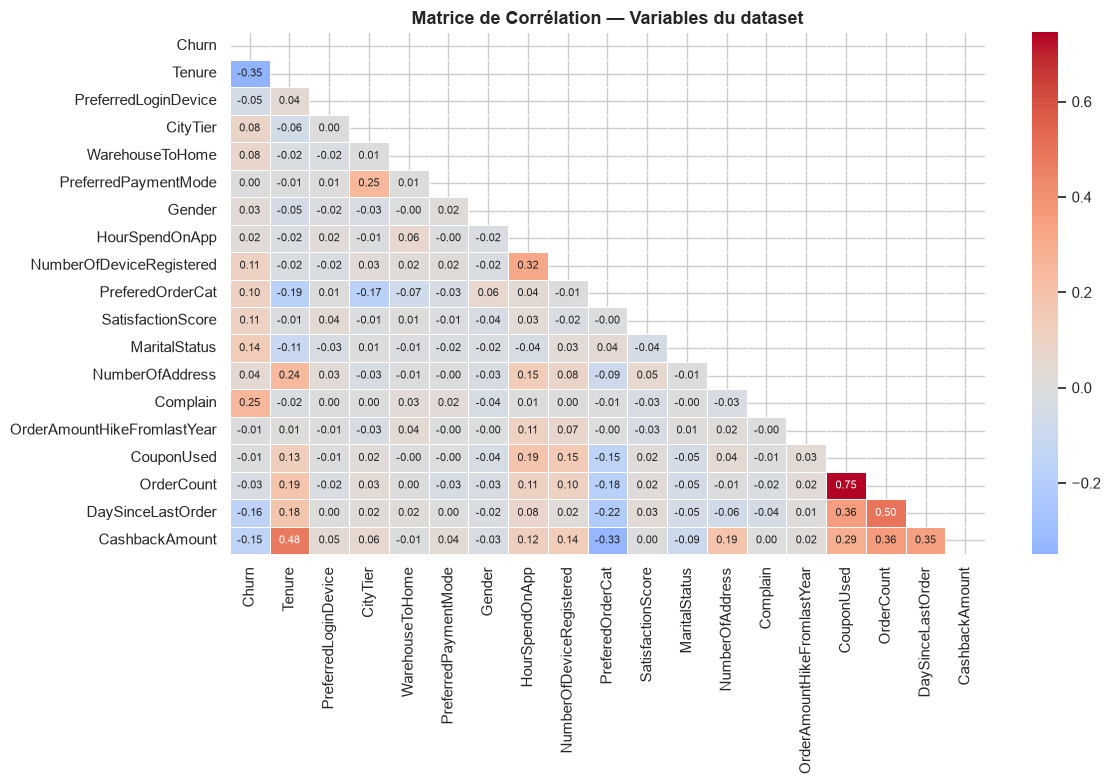

In [6]:
# 3.3 Matrice de corrélation
plt.figure(figsize=(12, 8))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5,
            annot_kws={"size": 8})
plt.title("Matrice de Corrélation — Variables du dataset", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('3_matrice_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

**Analyse – Matrice de corrélation**
- Les corrélations les plus fortes avec `Churn` sont `Tenure` (-0,35) et `Complain` (+0,25) :
  un client récent ayant déposé une réclamation est le profil le plus à risque.
- Viennent ensuite `DaySinceLastOrder` (-0,16) et `CashbackAmount` (-0,15).
- Les corrélations restent faibles à modérées : le churn dépend de combinaisons de variables,
  ce qui justifie un modèle non linéaire comme le Random Forest.

## 4. Feature engineering

In [7]:
# 4.1 Création de nouvelles variables
# Les features dérivées dépendent de colonnes contenant des valeurs manquantes : elles sont
# calculées dans le pipeline, juste après l'imputation (section 5).
def add_features(data):
    data = data.copy()
    data['orders_per_month'] = data['OrderCount'] / (data['Tenure'] + 1)
    data['avg_cashback_per_order'] = data['CashbackAmount'] / (data['OrderCount'] + 1)
    data['recency_ratio'] = data['DaySinceLastOrder'] / (data['Tenure'] + 1)
    return data

new_features = ['orders_per_month', 'avg_cashback_per_order', 'recency_ratio']
print("=== Nouvelles features (aperçu, avant imputation) ===")
print(add_features(df)[new_features].describe())

=== Nouvelles features (aperçu, avant imputation) ===
       orders_per_month  avg_cashback_per_order  recency_ratio
count       5108.000000             5372.000000    5059.000000
mean           0.611132               56.102842       0.905286
std            0.965765               24.540713       1.449340
min            0.016393                0.000000       0.000000
25%            0.125000               40.890000       0.181818
50%            0.300000               56.406667       0.481481
75%            1.000000               68.870000       1.000000
max           15.000000              149.295000      46.000000


## 5. Modélisation

In [8]:
# 5.1 Séparation features / cible
X = df.drop(columns=['Churn'])
y = df['Churn']

# 5.2 Train / test split (80/20, stratifié)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n=== Split dataset ===")
print(f"Train : {X_train.shape[0]} lignes | Test : {X_test.shape[0]} lignes")
print(f"Distribution cible (train) :\n{y_train.value_counts(normalize=True).round(3)}")

# 5.3 Pipeline imputation + feature engineering + SMOTE + Random Forest
# Toutes les étapes qui apprennent quelque chose des données (médianes, points synthétiques
# SMOTE) sont DANS le pipeline : elles ne voient que les données d'entraînement de chaque
# fold de validation croisée, puis du train final. Faites en amont, elles feraient fuiter
# de l'information du jeu de validation/test et gonfleraient l'AUC.
# Pas de normalisation : un Random Forest est insensible à l'échelle des variables.
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median').set_output(transform='pandas')),
    ('features', FunctionTransformer(add_features)),
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(random_state=42))
])

# 5.4 GridSearchCV — Random Forest
param_grid = {
    'rf__n_estimators': [100, 200],
    'rf__max_depth': [None, 10, 20],
    'rf__min_samples_split': [2, 5],
    'rf__class_weight': ['balanced', None]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

print("\n=== GridSearchCV en cours... ===")
grid_search.fit(X_train, y_train)

print(f"\nMeilleurs hyperparamètres : {grid_search.best_params_}")
print(f"Meilleur score AUC (CV) : {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_


=== Split dataset ===
Train : 4504 lignes | Test : 1126 lignes
Distribution cible (train) :
Churn
0    0.832
1    0.168
Name: proportion, dtype: float64

=== GridSearchCV en cours... ===
Fitting 5 folds for each of 24 candidates, totalling 120 fits



Meilleurs hyperparamètres : {'rf__class_weight': None, 'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 200}
Meilleur score AUC (CV) : 0.9773


## 6. Évaluation du modèle


=== Rapport de classification ===
              precision    recall  f1-score   support

      Fidèle       0.99      0.99      0.99       936
     Churner       0.94      0.97      0.95       190

    accuracy                           0.98      1126
   macro avg       0.97      0.98      0.97      1126
weighted avg       0.98      0.98      0.98      1126

AUC-ROC : 0.9983


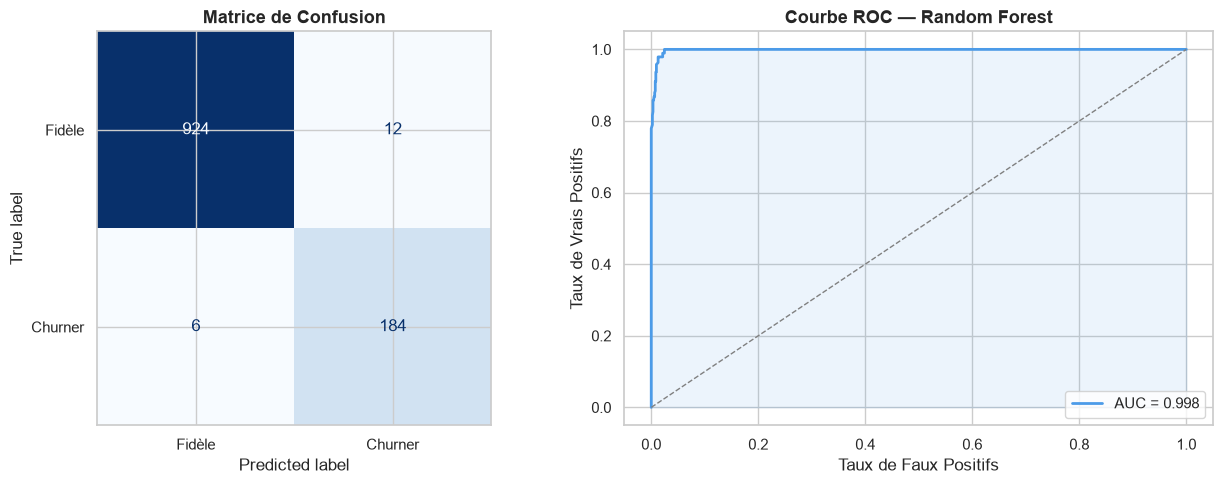

In [9]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("\n=== Rapport de classification ===")
print(classification_report(y_test, y_pred, target_names=['Fidèle', 'Churner']))

auc = roc_auc_score(y_test, y_proba)
print(f"AUC-ROC : {auc:.4f}")

# 6.1 Matrice de confusion
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fidèle', 'Churner'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title("Matrice de Confusion", fontsize=13, fontweight='bold')

# 6.2 Courbe ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#4C9BE8', lw=2, label=f'AUC = {auc:.3f}')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#4C9BE8')
axes[1].set_xlabel("Taux de Faux Positifs")
axes[1].set_ylabel("Taux de Vrais Positifs")
axes[1].set_title("Courbe ROC — Random Forest", fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.savefig('4_evaluation_modele.png', dpi=150, bbox_inches='tight')
plt.show()

**Analyse – Évaluation du modèle**
- AUC-ROC de 0,998 sur le jeu de test (0,977 en validation croisée) : excellent pouvoir discriminant.
- Le modèle détecte 97 % des churners (rappel) avec une précision de 94 % sur cette classe.
- L'imputation et SMOTE, appris uniquement sur les données d'entraînement de chaque fold,
  corrigent valeurs manquantes et déséquilibre sans biaiser l'évaluation.
- Limite : ce dataset Kaggle est très « propre ». Des performances aussi élevées sont rares
  en production et devraient être revalidées sur des données réelles.

## 7. Importance des features

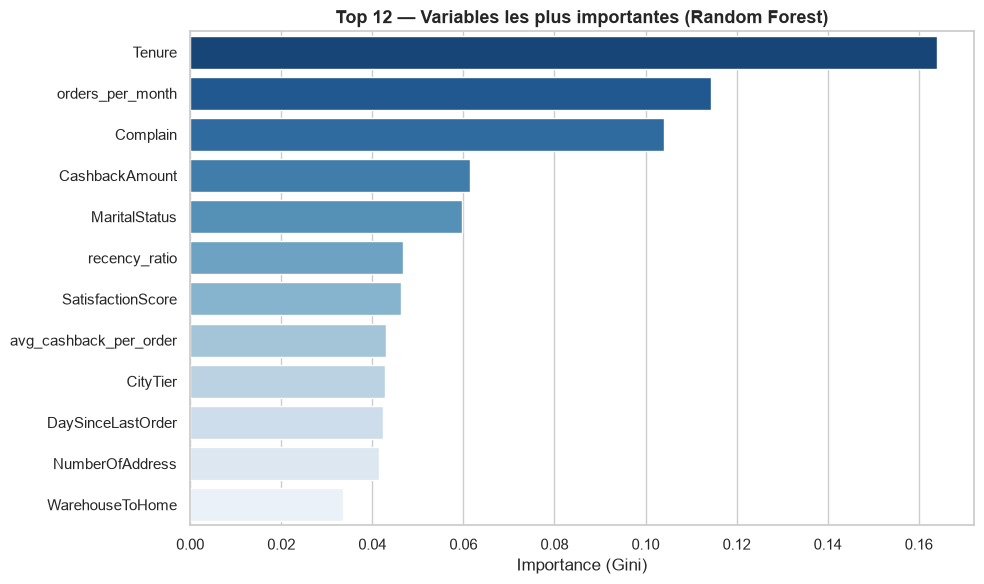

In [10]:
importances = best_model.named_steps['rf'].feature_importances_
feat_imp = pd.DataFrame({
    'feature': best_model.named_steps['rf'].feature_names_in_,  # inclut les features dérivées
    'importance': importances
}).sort_values('importance', ascending=False).head(12)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp, x='importance', y='feature',
            palette='Blues_r', edgecolor='white')
plt.title("Top 12 — Variables les plus importantes (Random Forest)", fontsize=13, fontweight='bold')
plt.xlabel("Importance (Gini)")
plt.ylabel("")
plt.tight_layout()
plt.savefig('5_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

**Analyse – Importance des variables**
- L'ancienneté (Tenure) est de loin la variable la plus prédictive, suivie de la feature
  dérivée `orders_per_month` (elle-même fortement liée à l'ancienneté).
- Les réclamations (`Complain`) arrivent en 3e position, devant le cashback (`CashbackAmount`)
  et la situation maritale (`MaritalStatus`).
- Pour les équipes CRM, la priorité est donc l'onboarding : les premiers mois de la relation
  client, et le traitement rapide des réclamations, sont les leviers de rétention clés.

## 8. Scoring de fidélité


AUC-ROC out-of-fold (base complète) : 0.9913

=== Répartition des segments de fidélité ===
loyalty_segment
À risque     824
Instable     172
Stable       380
Fidèle      4254
Name: count, dtype: int64

=== Taux de churn réel par segment ===
loyalty_segment
À risque    0.950
Instable    0.576
Stable      0.121
Fidèle      0.005
Name: churn_reel, dtype: float64


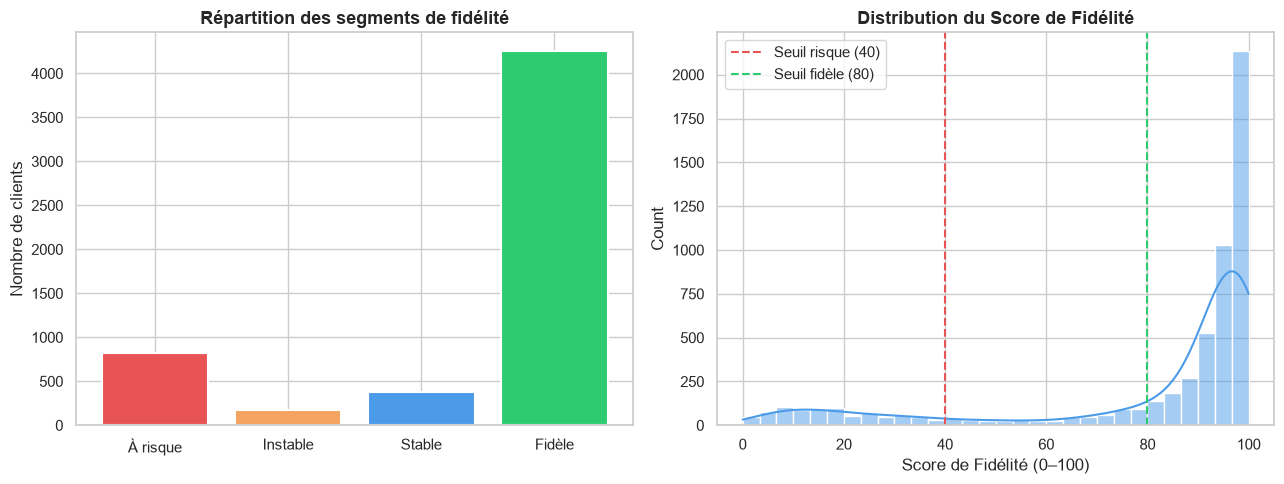


✅ Fichier 'loyalty_scores_output.csv' exporté pour Power BI.


In [11]:
# Score = probabilité de NE PAS churner (fidélité), calculé pour TOUTE la base client.
# Prédictions "out-of-fold" : chaque client est scoré par un modèle (mêmes hyperparamètres
# que best_model) entraîné sans lui. Scorer les clients d'entraînement avec best_model
# donnerait des scores sur-confiants, le Random Forest ayant mémorisé ces clients.
oof_proba = cross_val_predict(best_model, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
print(f"\nAUC-ROC out-of-fold (base complète) : {roc_auc_score(y, oof_proba):.4f}")

df_score = pd.DataFrame({'CustomerID': customer_ids, 'churn_reel': y})
df_score['churn_proba'] = oof_proba
df_score['loyalty_score'] = (1 - oof_proba) * 100  # Score de 0 à 100
df_score['loyalty_segment'] = pd.cut(
    df_score['loyalty_score'],
    bins=[0, 40, 60, 80, 100],
    labels=['À risque', 'Instable', 'Stable', 'Fidèle'],
    include_lowest=True  # sinon un score de exactement 0 tombe hors segment (NaN)
)

print("\n=== Répartition des segments de fidélité ===")
print(df_score['loyalty_segment'].value_counts().sort_index())

print("\n=== Taux de churn réel par segment ===")
print(df_score.groupby('loyalty_segment', observed=True)['churn_reel'].mean().round(3))

# Visualisation des segments
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

segment_colors = {'À risque': '#E85454', 'Instable': '#F4A460',
                  'Stable': '#4C9BE8', 'Fidèle': '#2ECC71'}

counts = df_score['loyalty_segment'].value_counts().sort_index()
axes[0].bar(counts.index, counts.values,
            color=[segment_colors[s] for s in counts.index],
            edgecolor='white', linewidth=1.5)
axes[0].set_title("Répartition des segments de fidélité", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Nombre de clients")
axes[0].set_xlabel("")

sns.histplot(df_score['loyalty_score'], bins=30, kde=True,
             color='#4C9BE8', ax=axes[1])
axes[1].axvline(40, color='#E85454', linestyle='--', linewidth=1.5, label='Seuil risque (40)')
axes[1].axvline(80, color='#2ECC71', linestyle='--', linewidth=1.5, label='Seuil fidèle (80)')
axes[1].set_title("Distribution du Score de Fidélité", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Score de Fidélité (0–100)")
axes[1].legend()

plt.tight_layout()
plt.savefig('6_scoring_fidelite.png', dpi=150, bbox_inches='tight')
plt.show()

# Export CSV pour Power BI
df_score[['CustomerID', 'loyalty_score', 'loyalty_segment', 'churn_proba', 'churn_reel']].to_csv(
    'loyalty_scores_output.csv', index=False)
print("\n✅ Fichier 'loyalty_scores_output.csv' exporté pour Power BI.")

**Analyse – Scoring de la base complète**
- Les 5 630 clients sont scorés (AUC-ROC out-of-fold : 0,991).
- Les segments sont cohérents avec le churn réel : 95 % de churners dans « À risque »,
  58 % dans « Instable », 12 % dans « Stable » et moins de 1 % dans « Fidèle ».
- Le segment « À risque » (824 clients) concentre l'essentiel des churners et constitue
  la cible prioritaire des campagnes de rétention.

## Conclusion

Ce projet a permis de construire un pipeline complet de modélisation prédictive :

1. **Exploration & nettoyage** : identification des valeurs manquantes, analyse des distributions et corrélations.
2. **Feature engineering** : création de variables comportementales dérivées (commandes par mois, ratio de récence).
3. **Modélisation** : pipeline sans fuite de données (imputation par la médiane, features dérivées, rééquilibrage SMOTE, Random Forest) optimisé via GridSearchCV avec validation croisée stratifiée (5 folds).
4. **Évaluation** : AUC-ROC de 0,998 sur le test, 97 % des churners détectés.
5. **Scoring** : génération d'un score de fidélité de 0 à 100 pour l'ensemble des clients (prédictions out-of-fold), segmenté en 4 catégories actionnables pour les équipes CRM.

**Export Power BI** : le fichier `loyalty_scores_output.csv` peut être directement importé dans Power BI pour construire un dashboard de suivi de la fidélité client.